# How Do Cyclistic Casual Riders and Annual Members Use Bikes Differently?

## A Data-Driven Marketing Analysis

**Dataset:** Divvy 2019 Trip Data

**Study Period:** January – December 2019

**Records Analysed:** 3,816,067 rides

**Tools:** Python, Pandas, Matplotlib and Seaborn

### Business Question

How do annual members and casual riders use Cyclistic bikes differently, and how can these differences help convert casual riders into annual members?

In [1]:
import urllib.request
import zipfile
import os

# Official Divvy data S3 bucket URL
BASE_URL = "https://divvy-tripdata.s3.amazonaws.com/"

# 2019 Quarterly zip files
ZIPS = [
    "Divvy_Trips_2019_Q1.zip",
    "Divvy_Trips_2019_Q2.zip",
    "Divvy_Trips_2019_Q3.zip",
    "Divvy_Trips_2019_Q4.zip"
]

print("Downloading and extracting full 2019 Divvy datasets...")
for zip_file in ZIPS:
    zip_path = f"/content/{zip_file}"
    # Download if not exists
    if not os.path.exists(zip_path):
        print(f"Downloading {zip_file}...")
        urllib.request.urlretrieve(BASE_URL + zip_file, zip_path)

    # Extract
    print(f"Extracting {zip_file}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("/content")

print("\nAll 4 quarters downloaded and extracted! You can now run Phase 2.")

Extracting Divvy_Trips_2019_Q1.zip...
Extracting Divvy_Trips_2019_Q2.zip...
Extracting Divvy_Trips_2019_Q3.zip...
Extracting Divvy_Trips_2019_Q4.zip...

All 4 quarters downloaded and extracted! You can now run Phase 2.


In [2]:
"""
Cyclistic Capstone | Phase 2: Prepare
Load 4 quarterly Divvy files, harmonize schema, combine, validate.
NO cleaning here (that is Phase 3). We only make the data loadable and auditable.
"""
from pathlib import Path
import pandas as pd

# ---- CONFIG: point this at the folder holding your 4 CSVs -------------------
DATA_DIR = Path("/content")   # change to your local folder
OUT_DIR = Path(".")                          # where the combined file is saved
# -----------------------------------------------------------------------------

STD_COLS = [
    "trip_id", "start_time", "end_time", "bikeid", "tripduration",
    "from_station_id", "from_station_name", "to_station_id", "to_station_name",
    "usertype", "gender", "birthyear",
]


def load_quarter(q: int) -> pd.DataFrame:
    """Q2 ships with verbose headers ('01 - Rental Details ...'), so we ignore
    the file's header and apply the standard names by position.
    thousands=',' fixes durations stored as strings like '1,048.0'."""
    df = pd.read_csv(
        DATA_DIR / f"Divvy_Trips_2019_Q{q}.csv",
        header=0, names=STD_COLS, thousands=",", low_memory=False,
    )
    df["source_quarter"] = f"Q{q}"
    return df


frames = [load_quarter(q) for q in (1, 2, 3, 4)]
trips = pd.concat(frames, ignore_index=True)

# ---- Type fixes (parsing only, no row removal) ------------------------------
trips["start_time"] = pd.to_datetime(trips["start_time"], errors="coerce")
trips["end_time"] = pd.to_datetime(trips["end_time"], errors="coerce")
trips["tripduration"] = trips["tripduration"].astype("float64")
trips["usertype"] = trips["usertype"].astype("category")

# ---- Validation checks (these feed your Data Quality Log) -------------------
print("Rows per quarter:\n", trips["source_quarter"].value_counts().sort_index(), "\n")
print("Total rows:", len(trips))
print("Date range:", trips["start_time"].min(), "->", trips["start_time"].max())
print("Duplicate trip_ids:", trips["trip_id"].duplicated().sum())
print("\nUsertype counts:\n", trips["usertype"].value_counts(dropna=False))
print("\nNulls:\n", trips.isna().sum()[lambda s: s > 0])
print("\nUsertype share by quarter:\n",
      pd.crosstab(trips["source_quarter"], trips["usertype"], normalize="index").round(3))

# ---- Save the combined raw file for Phase 3 ---------------------------------
try:
    trips.to_parquet(OUT_DIR / "trips_2019_raw.parquet", index=False)
    print("\nSaved trips_2019_raw.parquet")
except ImportError:  # pyarrow not installed
    trips.to_pickle(OUT_DIR / "trips_2019_raw.pkl")
    print("\nSaved trips_2019_raw.pkl (install pyarrow for parquet)")

Rows per quarter:
 source_quarter
Q1     365069
Q2    1108163
Q3    1640718
Q4     704054
Name: count, dtype: int64 

Total rows: 3818004
Date range: 2019-01-01 00:04:37 -> 2019-12-31 23:57:17
Duplicate trip_ids: 0

Usertype counts:
 usertype
Subscriber    2937367
Customer       880637
Name: count, dtype: int64

Nulls:
 gender       559206
birthyear    538751
dtype: int64

Usertype share by quarter:
 usertype        Customer  Subscriber
source_quarter                      
Q1                 0.063       0.937
Q2                 0.234       0.766
Q3                 0.300       0.700
Q4                 0.151       0.849

Saved trips_2019_raw.parquet


In [3]:
"""
Cyclistic Capstone | Phase 3: Process
Input : trips_2019_raw.(parquet|pkl) produced by phase2_prepare.py
Output: trips_2019_clean.(parquet|pkl) + cleaning_log.csv

Every removal is logged sequentially (counts are AFTER earlier steps), so the
log reconciles exactly: raw rows - rows removed = clean rows.
"""
from pathlib import Path
import pandas as pd

IN_DIR = Path(".")    # folder containing phase 2 output
OUT_DIR = Path(".")   # where clean data + log are saved

MIN_RIDE_SEC = 60                    # Divvy already enforces this; kept as a guard
MAX_RIDE_SEC = 24 * 3600             # exclude likely unreturned / lost bikes
TEST_STATION_PATTERN = r"TEST|HQ|WAREHOUSE|LBS"
BIRTHYEAR_MIN, BIRTHYEAR_MAX = 1930, 2005

DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MONTH_ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
SEASON_MAP = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}

# ---------------------------------------------------------------- load + rename
pq, pk = IN_DIR / "trips_2019_raw.parquet", IN_DIR / "trips_2019_raw.pkl"
df = pd.read_parquet(pq) if pq.exists() else pd.read_pickle(pk)

# Align with the case-study naming (member_casual, started_at, ended_at ...)
df = df.rename(columns={
    "trip_id": "ride_id", "start_time": "started_at", "end_time": "ended_at",
    "from_station_id": "start_station_id", "from_station_name": "start_station_name",
    "to_station_id": "end_station_id", "to_station_name": "end_station_name",
    "usertype": "member_casual", "tripduration": "ride_length_sec",
})

# Map usertype values
df["member_casual"] = df["member_casual"].astype(str).str.strip().map(
    {"Subscriber": "member", "Customer": "casual"}
)

# ---------------------------------------------------------------- cleaning log
log = []
raw_rows = len(df)


def record(step, removed, action, rule):
    log.append({"step": step, "rows_affected": int(removed), "rows_remaining": len(df),
                "action": action, "rule": rule})


record("0. Raw combined (Q1-Q4)", 0, "none", "Loaded 4 quarterly files, harmonized schema")


def drop(mask, step, rule):
    global df
    n = int(mask.sum())
    df = df.loc[~mask].copy()
    record(step, n, "rows dropped", rule)


# 1a. Missing / Unexpected Usertypes
drop(df["member_casual"].isna(), "1a. Invalid usertype", "Usertype was null or could not be mapped to member/casual")

# 1b. Duplicates
drop(df["ride_id"].duplicated(), "1b. Duplicate ride_id", "Same ride_id appears more than once")

# 2. Impossible timestamps
drop(df["ended_at"].isna() | df["started_at"].isna() | (df["ended_at"] < df["started_at"]), "2. Invalid or End before start",
     "Timestamps are null or ended_at < started_at (all on 2019-11-03 DST change)")

# 3. Test / warehouse stations
test_mask = (df["start_station_name"].str.contains(TEST_STATION_PATTERN, case=False, regex=True, na=False)
             | df["end_station_name"].str.contains(TEST_STATION_PATTERN, case=False, regex=True, na=False))
drop(test_mask, "3. Test/warehouse stations", f"Station name matches /{TEST_STATION_PATTERN}/i")

# 4. Ride-length bounds
drop(df["ride_length_sec"] < MIN_RIDE_SEC, "4a. Ride under 60s", "Guard rule (likely false starts)")
drop(df["ride_length_sec"] > MAX_RIDE_SEC, "4b. Ride over 24h", "Likely unreturned or lost bikes")

# 5. Implausible birth years -> NaN (row is kept; value is not trusted)
bad_by = df["birthyear"].notna() & ~df["birthyear"].between(BIRTHYEAR_MIN, BIRTHYEAR_MAX)
df.loc[bad_by, "birthyear"] = pd.NA
record("5. Implausible birth year", bad_by.sum(), "values set to NaN",
       f"birthyear outside {BIRTHYEAR_MIN}-{BIRTHYEAR_MAX}")

# 6. Canonical station names (24 IDs carry more than one name over the year)
pairs = pd.concat([
    df[["start_station_id", "start_station_name"]].set_axis(["id", "name"], axis=1),
    df[["end_station_id", "end_station_name"]].set_axis(["id", "name"], axis=1),
])
counts = pairs.value_counts().reset_index(name="n").sort_values("n", ascending=False)
canon = counts.drop_duplicates("id").set_index("id")["name"]
renamed_ids = int(counts.groupby("id")["name"].nunique().gt(1).sum())
changed = int((df["start_station_name"] != df["start_station_id"].map(canon)).sum())
df["start_station_name"] = df["start_station_id"].map(canon)
df["end_station_name"] = df["end_station_id"].map(canon)
record("6. Canonical station names", changed, "values standardized",
       f"{renamed_ids} station IDs had multiple names; mapped each ID to its most frequent name")

# ---------------------------------------------------------------- feature engineering
s = df["started_at"]
df["ride_length_min"] = df["ride_length_sec"] / 60
df["day_of_week"] = (s.dt.dayofweek + 1) % 7 + 1          # 1=Sunday ... 7=Saturday (case-study convention)
df["day_name"] = pd.Categorical(s.dt.day_name(), categories=DAY_ORDER, ordered=True)
df["hour"] = s.dt.hour
df["month"] = s.dt.month
df["month_name"] = pd.Categorical(s.dt.strftime("%b"), categories=MONTH_ORDER, ordered=True)
df["quarter"] = s.dt.quarter
df["season"] = s.dt.month.map(SEASON_MAP)
df["is_weekend"] = s.dt.dayofweek >= 5
df["is_round_trip"] = df["start_station_id"] == df["end_station_id"]

for col in ["member_casual", "season", "start_station_name", "end_station_name", "gender", "source_quarter"]:
    df[col] = df[col].astype("category")

# ---------------------------------------------------------------- validation
core = ["ride_id", "started_at", "ended_at", "member_casual",
        "start_station_id", "end_station_id", "ride_length_sec"]
assert df[core].notna().all().all(), "Nulls in core columns"
assert df["ride_id"].is_unique
assert (df["ended_at"] >= df["started_at"]).all()
assert df["ride_length_sec"].between(MIN_RIDE_SEC, MAX_RIDE_SEC).all()
assert set(df["member_casual"].unique()) == {"member", "casual"}
assert df["start_station_name"].notna().all() and df["end_station_name"].notna().all()
removed_total = sum(r["rows_affected"] for r in log if r["action"] == "rows dropped")
assert raw_rows - removed_total == len(df), "Log does not reconcile with row count"

log_df = pd.DataFrame(log)
print(log_df[["step", "rows_affected", "rows_remaining", "action"]].to_string(index=False))
print(f"\nClean rows: {len(df):,} ({len(df) / raw_rows:.3%} of raw retained)")
print("\nmember_casual:\n", df["member_casual"].value_counts().to_string())
print("\nAll validation checks passed.")

# ---------------------------------------------------------------- save
log_df.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
try:
    df.to_parquet(OUT_DIR / "trips_2019_clean.parquet", index=False)
    print("Saved trips_2019_clean.parquet")
except ImportError:
    df.to_pickle(OUT_DIR / "trips_2019_clean.pkl")
    print("Saved trips_2019_clean.pkl (install pyarrow for parquet)")

                          step  rows_affected  rows_remaining              action
       0. Raw combined (Q1-Q4)              0         3818004                none
          1a. Invalid usertype              0         3818004        rows dropped
         1b. Duplicate ride_id              0         3818004        rows dropped
2. Invalid or End before start             13         3817991        rows dropped
    3. Test/warehouse stations            172         3817819        rows dropped
            4a. Ride under 60s              0         3817819        rows dropped
             4b. Ride over 24h           1752         3816067        rows dropped
     5. Implausible birth year           1042         3816067   values set to NaN
    6. Canonical station names          70714         3816067 values standardized

Clean rows: 3,816,067 (99.949% of raw retained)

member_casual:
 member_casual
member    2936805
casual     879262

All validation checks passed.
Saved trips_2019_clean.parquet


In [4]:
"""
Cyclistic Capstone | Phase 4: Analyze
Input : trips_2019_clean.(parquet|pkl) from phase3_process.py
Output: summary/*.csv  (one table per finding, reused for Phase 5 charts)

Lens order: Baseline -> Seasonality -> When -> How long -> Where -> Conversion segment
"""
from pathlib import Path
import pandas as pd

IN_DIR = Path(".")
OUT_DIR = Path("summary")
OUT_DIR.mkdir(exist_ok=True)
pd.options.display.float_format = "{:,.1f}".format
pd.options.display.width = 140

pq, pk = IN_DIR / "trips_2019_clean.parquet", IN_DIR / "trips_2019_clean.pkl"
df = pd.read_parquet(pq) if pq.exists() else pd.read_pickle(pk)
G = dict(observed=True)


def save(tbl, name):
    tbl.to_csv(OUT_DIR / f"{name}.csv")
    return tbl


def section(title):
    print(f"\n{'=' * 8} {title} {'=' * 8}")


# ------------------------------------------------------------------ 0. BASELINE (case-study stats)
section("0. BASELINE")
print(f"Rides: {len(df):,} | mean ride: {df.ride_length_min.mean():.1f} min | "
      f"max ride: {df.ride_length_min.max():.0f} min | modal weekday: {df.day_name.mode()[0]}")
base = df.groupby("member_casual", **G).agg(
    rides=("ride_id", "count"),
    mean_min=("ride_length_min", "mean"),
    median_min=("ride_length_min", "median"),
    p90_min=("ride_length_min", lambda s: s.quantile(0.9)),
    modal_day=("day_name", lambda s: s.mode()[0]),
)
base["share_of_rides_pct"] = base["rides"] / base["rides"].sum() * 100
print(save(base, "01_baseline_by_type"))

# ------------------------------------------------------------------ 1. SEASONALITY
section("1. SEASONALITY (rides by month)")
month = df.pivot_table(index="month_name", columns="member_casual", values="ride_id",
                       aggfunc="count", observed=True)
month["casual_share_pct"] = month["casual"] / (month["casual"] + month["member"]) * 100
print(save(month, "02_monthly_rides"))
summer = df["month"].isin([6, 7, 8, 9])
for t in ("casual", "member"):
    sub = df[df.member_casual == t]
    print(f"{t}: {sub['month'].isin([6, 7, 8, 9]).mean() * 100:.1f}% of rides occur Jun-Sep")

# ------------------------------------------------------------------ 2. WHEN
section("2a. WEEKDAY")
wd = df.pivot_table(index="day_name", columns="member_casual", values="ride_id",
                    aggfunc="count", observed=True)
wd_share = wd / wd.sum() * 100
wd_share.columns = [f"{c}_pct_of_type" for c in wd_share.columns]
wd_med = df.groupby(["day_name", "member_casual"], **G)["ride_length_min"].median().unstack()
wd_med.columns = [f"{c}_median_min" for c in wd_med.columns]
print(save(pd.concat([wd, wd_share, wd_med], axis=1), "03_weekday"))
print("Weekend share of rides:\n",
      (df.groupby("member_casual", **G)["is_weekend"].mean() * 100).round(1).to_string())

section("2b. HOUR OF DAY (share of each type's rides, weekday vs weekend)")
df["daypart"] = df["is_weekend"].map({True: "weekend", False: "weekday"})
hourly = (df.groupby(["daypart", "member_casual", "hour"], **G).size()
          .groupby(level=[0, 1], observed=True).transform(lambda s: s / s.sum() * 100)
          .rename("pct_of_type_daypart").reset_index())
save(hourly.set_index(["daypart", "member_casual", "hour"]), "04_hourly_profile")
for (dp, t), g in hourly.groupby(["daypart", "member_casual"], observed=True):
    top = g.nlargest(3, "pct_of_type_daypart")
    print(f"{dp:8s} {t:7s} top hours: " +
          ", ".join(f"{int(h):02d}:00 ({p:.1f}%)" for h, p in zip(top.hour, top.pct_of_type_daypart)))

COMMUTE_HOURS = [7, 8, 9, 16, 17, 18]
df["commute_window"] = (~df["is_weekend"]) & df["hour"].isin(COMMUTE_HOURS)
print("\nShare of rides in weekday commute windows (07-09h, 16-18h):\n",
      (df.groupby("member_casual", **G)["commute_window"].mean() * 100).round(1).to_string())

# ------------------------------------------------------------------ 3. HOW LONG
section("3. RIDE LENGTH")
df["over_30"] = df["ride_length_min"] > 30
df["over_60"] = df["ride_length_min"] > 60
dur = df.groupby("member_casual", **G).agg(
    median_min=("ride_length_min", "median"),
    pct_over_30min=("over_30", "mean"),
    pct_over_60min=("over_60", "mean"),
)
dur[["pct_over_30min", "pct_over_60min"]] *= 100
print(save(dur, "05_duration_summary"))
season_med = df.groupby(["season", "member_casual"], **G)["ride_length_min"].median().unstack()
print("\nMedian ride (min) by season:\n", save(season_med, "06_duration_by_season"))
rt = df.groupby("member_casual", **G)["is_round_trip"].mean() * 100
print("\nRound-trip share of rides (%):\n", rt.round(1).to_string())

# ------------------------------------------------------------------ 4. WHERE
section("4. WHERE (casual hot-spots)")
cas = df[df.member_casual == "casual"]
top = (cas.groupby("start_station_name", **G).size().rename("casual_rides").to_frame()
       .assign(pct_of_casual=lambda t: t.casual_rides / len(cas) * 100)
       .sort_values("casual_rides", ascending=False).head(15))
tot = df.groupby("start_station_name", **G).size()
top["casual_share_at_station_pct"] = top.casual_rides / tot.reindex(top.index) * 100
top["round_trip_pct"] = (cas.groupby("start_station_name", **G)["is_round_trip"].mean() * 100).reindex(top.index)
print(save(top, "07_top_casual_start_stations"))
print(f"\nTop 10 stations = {top.casual_rides.head(10).sum() / len(cas) * 100:.1f}% of casual rides")
mem = df[df.member_casual == "member"]
mtop10 = mem.groupby("start_station_name", **G).size().nlargest(10).sum() / len(mem) * 100
print(f"Top 10 stations = {mtop10:.1f}% of member rides (for comparison)")
rtrip = (cas[cas.is_round_trip].groupby("start_station_name", **G).size()
         .nlargest(5).rename("casual_round_trips"))
print("\nTop casual round-trip stations:\n", rtrip.to_string())

# ------------------------------------------------------------------ 5. CONVERSION SEGMENT (rides, not riders)
section("5. 'MEMBER-LIKE' CASUAL RIDES (hypothesis segment)")
# Behaves like a member: weekday commute window, under 30 min, point-to-point
df["member_like"] = df["commute_window"] & (~df["over_30"]) & (~df["is_round_trip"])
seg = df.groupby("member_casual", **G)["member_like"].agg(["mean", "sum"])
seg["mean"] *= 100
seg.columns = ["pct_of_type_rides", "rides"]
print(save(seg, "08_member_like_rides"))
mlc = df[(df.member_casual == "casual") & df.member_like]
print("\nTop start stations for member-like casual rides:\n",
      mlc.groupby("start_station_name", **G).size().nlargest(8).to_string())
print("\nMember-like casual rides by month:\n",
      mlc.groupby("month_name", **G).size().to_string())
print(f"\nSummary tables saved to ./{OUT_DIR}/")



======== 0. BASELINE ========
Rides: 3,816,067 | mean ride: 19.0 min | max ride: 1440 min | modal weekday: Thursday
                 rides  mean_min  median_min  p90_min modal_day  share_of_rides_pct
member_casual                                                                      
casual          879262      39.4        25.8     80.8  Saturday                23.0
member         2936805      12.9         9.8     24.9   Tuesday                77.0

======== 1. SEASONALITY (rides by month) ========
member_casual  casual  member  casual_share_pct
month_name                                     
Jan              4591   98601               4.4
Feb              2627   93522               2.7
Mar             15877  149659               9.6
Apr             47669  217531              18.0
May             81506  285792              22.2
Jun            130065  345135              27.4
Jul            175429  381610              31.5
Aug            186620  403225              31.6
Sep            1

## Load clean data, configure the notebook, and generate the seasonality chart

Run this cell first. It installs `pyarrow` only when a Parquet file is selected and the engine is unavailable.

In [5]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# ---------------------------------------------------------------------
# 1. Google Colab data input
# ---------------------------------------------------------------------
# Option A (recommended): leave DATA_PATH blank and upload the cleaned
# trips_2019_clean.parquet or trips_2019_clean.pkl file when prompted.
#
# Option B: mount Google Drive and enter the full file path below.
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_PATH = "/content/drive/MyDrive/your-folder/trips_2019_clean.parquet"

DATA_PATH = ""  # Set a Google Drive path here, or leave blank to upload.

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    files = None
    IN_COLAB = False

BASE_DIR = Path.cwd()
OUT_DIR = BASE_DIR / "charts"
OUT_DIR.mkdir(parents=True, exist_ok=True)

if DATA_PATH.strip():
    data_path = Path(DATA_PATH).expanduser()
    if not data_path.exists():
        raise FileNotFoundError(f"DATA_PATH was not found: {data_path}")
else:
    supported = {".parquet", ".pkl"}
    candidates = [
        p for p in BASE_DIR.iterdir()
        if p.is_file() and p.suffix.lower() in supported
    ]

    # Prefer the expected cleaned dataset name when more than one file exists.
    preferred = [
        p for p in candidates
        if p.name.lower() in {"trips_2019_clean.parquet", "trips_2019_clean.pkl"}
    ]
    candidates = preferred or candidates

    if not candidates:
        if not IN_COLAB:
            raise FileNotFoundError(
                "No .parquet or .pkl file found. Set DATA_PATH to your cleaned dataset."
            )
        print("Upload trips_2019_clean.parquet or trips_2019_clean.pkl")
        uploaded = files.upload()
        candidates = [
            BASE_DIR / name for name in uploaded
            if Path(name).suffix.lower() in supported
        ]

    if not candidates:
        raise FileNotFoundError(
            "No supported file was selected. Upload a .parquet or .pkl cleaned dataset."
        )

    data_path = candidates[0]
    if len(candidates) > 1:
        print(f"Multiple supported files found; using: {data_path.name}")

# ---------------------------------------------------------------------
# 2. Load and validate the cleaned dataset
# ---------------------------------------------------------------------
if data_path.suffix.lower() == ".parquet":
    try:
        df = pd.read_parquet(data_path)
    except ImportError:
        print("Parquet engine not found. Installing pyarrow for Google Colab...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyarrow"])
        df = pd.read_parquet(data_path)
elif data_path.suffix.lower() == ".pkl":
    df = pd.read_pickle(data_path)
else:
    raise ValueError("Dataset must be a .parquet or .pkl file.")

REQUIRED_COLUMNS = [
    "member_casual", "month", "day_name", "hour",
    "is_weekend", "ride_length_min", "start_station_name"
]
missing_columns = [col for col in REQUIRED_COLUMNS if col not in df.columns]
if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

df = df[REQUIRED_COLUMNS].copy()

# Standardise rider labels and exclude unexpected values.
raw_rider = df["member_casual"].astype("string").str.strip().str.lower()
rider_map = {"casual": "Casual", "member": "Member"}
df["rider"] = raw_rider.map(rider_map)
invalid_riders = df["rider"].isna().sum()
if invalid_riders:
    print(f"Rows excluded for unknown/missing rider type: {invalid_riders:,}")
df = df.loc[df["rider"].notna()].copy()

# Convert numeric fields safely. Invalid values are handled within each analysis.
for col in ["month", "hour", "ride_length_min"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Normalise weekday names while accepting both full names and abbreviations.
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_lookup = {day.lower(): day for day in WEEKDAYS}
day_lookup.update({day[:3].lower(): day for day in WEEKDAYS})
df["day_name"] = (
    df["day_name"].astype("string").str.strip().str.lower().map(day_lookup)
)

# Parse boolean weekend indicators without treating the string "False" as True.
def parse_weekend(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    value = str(value).strip().lower()
    if value in {"true", "1", "yes", "y"}:
        return True
    if value in {"false", "0", "no", "n"}:
        return False
    return np.nan

df["is_weekend"] = df["is_weekend"].map(parse_weekend)

N = len(df)
CASUAL, MEMBER = "#D55E00", "#0072B2"  # Okabe-Ito colourblind-safe palette
PALETTE = {"Casual": CASUAL, "Member": MEMBER}
MARKERS = {"Casual": "o", "Member": "s"}
INK, MUTED = "#222222", "#555555"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
RIDER_ORDER = ["Casual", "Member"]
ALT = {}

SOURCE = (
    "Source: Divvy 2019 trip data (Motivate International Inc., public license). "
    f"{N:,} cleaned rides loaded."
)

sns.set_theme(
    style="whitegrid",
    rc={
        "axes.edgecolor": "#BBBBBB",
        "grid.color": "#E6E6E6",
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "font.size": 11,
        "axes.titlesize": 12,
    },
)

def add_figure_header(fig, title, subtitle):
    """Add a consistent headline, subtitle, and source footer."""
    fig.text(
        0.015, 0.965, title, ha="left", va="top",
        fontsize=17, fontweight="bold", color=INK
    )
    fig.text(
        0.015, 0.895, subtitle, ha="left", va="top",
        fontsize=11, color=MUTED
    )
    fig.text(
        0.015, 0.015, SOURCE, ha="left", va="bottom",
        fontsize=10, color=MUTED
    )

def compact_count(value, _):
    """Format large counts as k, but keep small counts readable."""
    return f"{value / 1000:.0f}k" if abs(value) >= 1000 else f"{value:,.0f}"


def save_chart(fig, name, alt_text, insight):
    """Save, display, and register a chart and its written insight."""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
    plt.close(fig)
    ALT[name] = alt_text
    print(f"Saved: {OUT_DIR / (name + '.png')}")
    print(f"INSIGHT: {insight}")

print(f"Dataset loaded: {data_path.name}")
print(f"Cleaned records available: {N:,}")
print("Rider counts:")
print(df["rider"].value_counts().reindex(RIDER_ORDER, fill_value=0).rename("rides").to_string())

Dataset loaded: trips_2019_clean.parquet
Cleaned records available: 3,816,067
Rider counts:
rider
Casual     879262
Member    2936805


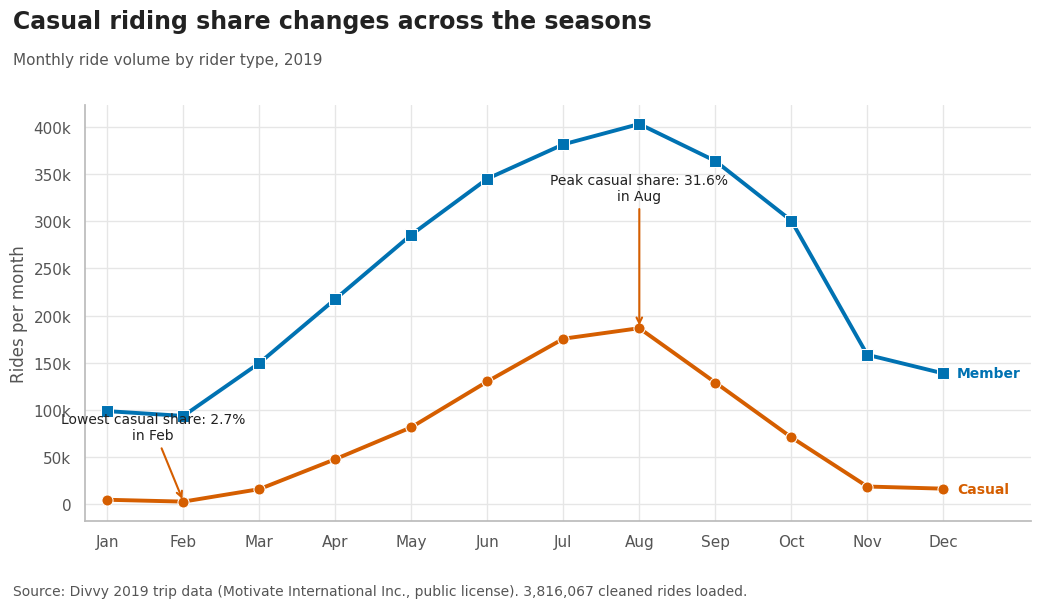

Saved: /kaggle/working/charts/01_seasonality.png
INSIGHT: Casual riders had their highest monthly ride volume in Aug (186,620 rides). Their largest monthly share was 31.6% in Aug. Member ride volume peaked in Aug.


In [6]:
# ---------------------------------------------------------------------
# Chart 1 — Seasonality
# ---------------------------------------------------------------------
season = df.dropna(subset=["month", "rider"]).copy()
season = season[season["month"].between(1, 12)]
season["month"] = season["month"].astype(int)

monthly = (
    season.groupby(["month", "rider"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=range(1, 13), columns=RIDER_ORDER, fill_value=0)
)

monthly_total = monthly.sum(axis=1)
casual_share = (monthly["Casual"] / monthly_total.replace(0, np.nan) * 100).dropna()

if casual_share.empty:
    raise ValueError("No valid month values were found for the seasonality analysis.")

monthly_long = (
    monthly.rename_axis("month")
    .reset_index()
    .melt(id_vars="month", var_name="rider", value_name="rides")
)

fig, ax = plt.subplots(figsize=(11, 6.2))
sns.lineplot(
    data=monthly_long, x="month", y="rides",
    hue="rider", style="rider",
    hue_order=RIDER_ORDER, style_order=RIDER_ORDER,
    palette=PALETTE, markers=MARKERS, dashes=False,
    linewidth=2.8, markersize=8, legend=False, ax=ax
)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS)
ax.yaxis.set_major_formatter(FuncFormatter(compact_count))
ax.set_xlabel("")
ax.set_ylabel("Rides per month")
ax.set_xlim(0.7, 13.15)

# Direct labels make the series identifiable without relying on colour alone.
ax.text(12.18, monthly["Member"].iloc[-1], "Member",
        color=MEMBER, fontweight="bold", va="center", fontsize=10)
ax.text(12.18, monthly["Casual"].iloc[-1], "Casual",
        color=CASUAL, fontweight="bold", va="center", fontsize=10)

peak_month = int(casual_share.idxmax())
low_month = int(casual_share.idxmin())
peak_share = float(casual_share.loc[peak_month])
low_share = float(casual_share.loc[low_month])
y_max = max(float(monthly.to_numpy().max()), 1)

ax.annotate(
    f"Peak casual share: {peak_share:.1f}%\nin {MONTHS[peak_month - 1]}",
    xy=(peak_month, monthly.loc[peak_month, "Casual"]),
    xytext=(peak_month, y_max * 0.80),
    ha="center", fontsize=10, color=INK,
    arrowprops=dict(arrowstyle="->", color=CASUAL, lw=1.5)
)
ax.annotate(
    f"Lowest casual share: {low_share:.1f}%\nin {MONTHS[low_month - 1]}",
    xy=(low_month, monthly.loc[low_month, "Casual"]),
    xytext=(max(1, low_month - 0.4), y_max * 0.17),
    ha="center", fontsize=10, color=INK,
    arrowprops=dict(arrowstyle="->", color=CASUAL, lw=1.5)
)

sns.despine(ax=ax)
fig.subplots_adjust(top=0.81, bottom=0.14, left=0.08, right=0.94)
add_figure_header(
    fig,
    "Casual riding share changes across the seasons",
    "Monthly ride volume by rider type, 2019"
)

member_peak_month = int(monthly["Member"].idxmax())
casual_peak_month = int(monthly["Casual"].idxmax())
season_insight = (
    f"Casual riders had their highest monthly ride volume in {MONTHS[casual_peak_month - 1]} "
    f"({monthly.loc[casual_peak_month, 'Casual']:,} rides). Their largest monthly share "
    f"was {peak_share:.1f}% in {MONTHS[peak_month - 1]}. Member ride volume peaked in "
    f"{MONTHS[member_peak_month - 1]}."
)
season_alt = (
    f"Line chart of monthly rides by rider type in 2019. Casual ride share was highest "
    f"in {MONTHS[peak_month - 1]} at {peak_share:.1f}% and lowest in "
    f"{MONTHS[low_month - 1]} at {low_share:.1f}%. Casual ride volume peaked in "
    f"{MONTHS[casual_peak_month - 1]}, while member ride volume peaked in "
    f"{MONTHS[member_peak_month - 1]}."
)
save_chart(fig, "01_seasonality", season_alt, season_insight)

## Weekday versus weekend behaviour

Shows each rider group's share of rides by day, plus its weekend-ride percentage.

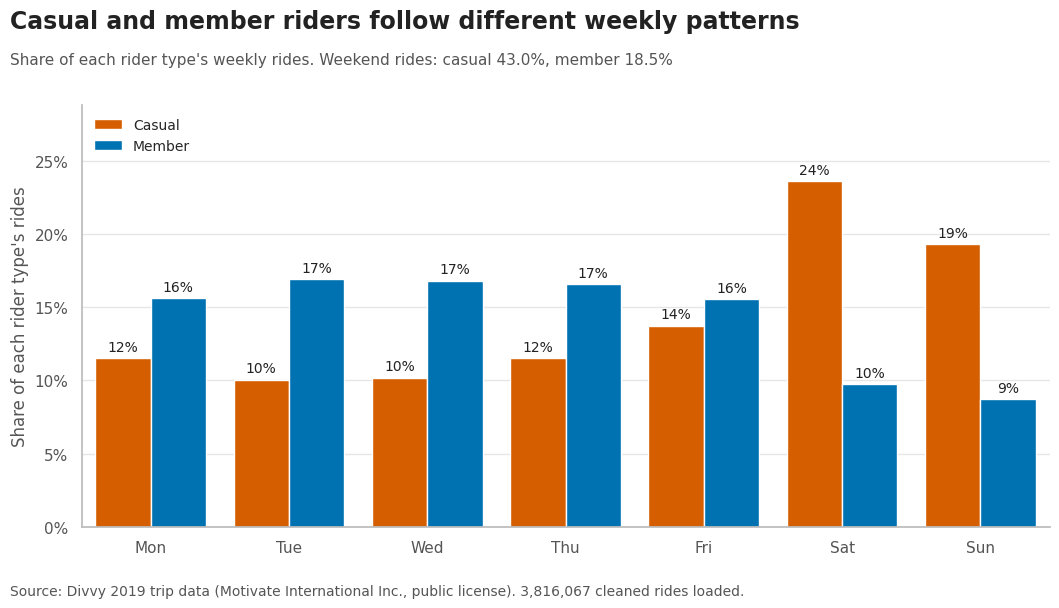

Saved: /kaggle/working/charts/02_weekday.png
INSIGHT: Weekend rides account for 43.0% of casual rides and 18.5% of member rides. Casual ride volume is highest on Saturday; member ride volume is highest on Tuesday.


In [7]:
# Use only records with a recognised weekday and a valid weekend flag.
weekday_data = df.dropna(subset=["day_name", "is_weekend", "rider"]).copy()
weekday_data = weekday_data[weekday_data["day_name"].isin(WEEKDAYS)]

if weekday_data.empty:
    raise ValueError("No valid weekday/weekend records are available.")

weekday_counts = (
    weekday_data.groupby(["day_name", "rider"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=WEEKDAYS, columns=RIDER_ORDER, fill_value=0)
)

# Each rider type is normalised to 100%, so the distributions are comparable.
weekday_pct = weekday_counts.div(
    weekday_counts.sum(axis=0).replace(0, np.nan), axis=1
) * 100

weekday_long = (
    weekday_pct.rename_axis("day_name")
    .reset_index()
    .melt(id_vars="day_name", var_name="rider", value_name="pct")
)
weekday_long["day_label"] = weekday_long["day_name"].str[:3]

fig, ax = plt.subplots(figsize=(11, 6.2))
sns.barplot(
    data=weekday_long,
    x="day_label", y="pct",
    hue="rider", order=[day[:3] for day in WEEKDAYS],
    hue_order=RIDER_ORDER, palette=PALETTE,
    saturation=1, ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container, fmt="%.0f%%", padding=3,
        fontsize=10, color=INK
    )

ax.set_xlabel("")
ax.set_ylabel("Share of each rider type's rides")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0f}%"))
max_pct = float(weekday_long["pct"].max())
ax.set_ylim(0, max(25, max_pct * 1.22))
ax.legend(title=None, frameon=False, loc="upper left", fontsize=10)
sns.despine(ax=ax)
fig.subplots_adjust(top=0.81, bottom=0.13, left=0.08, right=0.96)

weekend_share = weekday_data.groupby("rider")["is_weekend"].mean() * 100
casual_peak_day = weekday_counts["Casual"].idxmax()
member_peak_day = weekday_counts["Member"].idxmax()

add_figure_header(
    fig,
    "Casual and member riders follow different weekly patterns",
    (
        f"Share of each rider type's weekly rides. Weekend rides: "
        f"casual {weekend_share.get('Casual', np.nan):.1f}%, "
        f"member {weekend_share.get('Member', np.nan):.1f}%"
    )
)

casual_weekend = weekend_share.get("Casual", np.nan)
member_weekend = weekend_share.get("Member", np.nan)
weekday_insight = (
    f"Weekend rides account for {casual_weekend:.1f}% of casual rides and "
    f"{member_weekend:.1f}% of member rides. Casual ride volume is highest on "
    f"{casual_peak_day}; member ride volume is highest on {member_peak_day}."
)
weekday_alt = (
    f"Grouped bar chart showing each rider type's percentage of rides by weekday. "
    f"Weekend rides account for {casual_weekend:.1f}% of casual rides and "
    f"{member_weekend:.1f}% of member rides. Casual rides peak on {casual_peak_day}; "
    f"member rides peak on {member_peak_day}."
)

save_chart(fig, "02_weekday", weekday_alt, weekday_insight)

## Hour-of-day riding patterns

Compares the distribution of start hours for weekdays and weekends. The shaded weekday windows are contextual references.

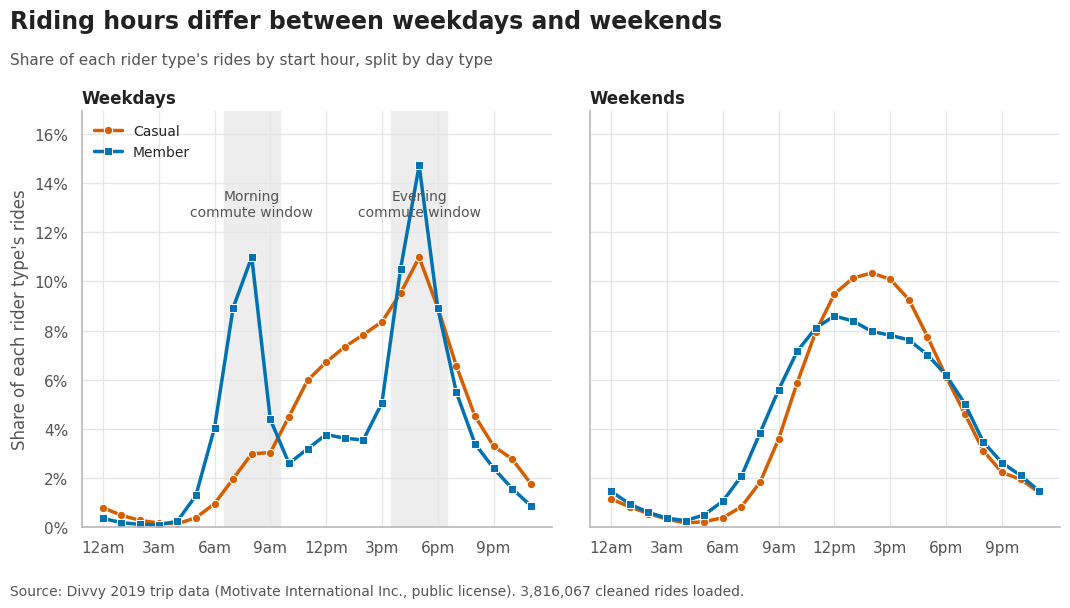

Saved: /kaggle/working/charts/03_hourly.png
INSIGHT: Peak start times — casual weekdays peak: 17:00; member weekdays peak: 17:00; casual weekends peak: 14:00; member weekends peak: 12:00. The weekday shaded areas indicate typical commute-time windows for reference.


In [8]:
# Hour-of-day patterns: weekdays versus weekends

hourly_data = df.dropna(subset=["is_weekend", "rider", "hour"]).copy()
hourly_data = hourly_data[hourly_data["hour"].between(0, 23)]
hourly_data["hour"] = hourly_data["hour"].astype(int)
hourly_data["daypart"] = np.where(
    hourly_data["is_weekend"], "Weekends", "Weekdays"
)

if hourly_data.empty:
    raise ValueError("No valid hour/weekend records are available.")

hourly = (
    hourly_data.groupby(["daypart", "rider", "hour"], observed=True)
    .size()
    .rename("rides")
    .reset_index()
)
hourly["pct"] = (
    hourly["rides"]
    / hourly.groupby(["daypart", "rider"], observed=True)["rides"].transform("sum")
    * 100
)

fig, axes = plt.subplots(1, 2, figsize=(11, 6.2), sharey=True)

for ax, daypart in zip(axes, ["Weekdays", "Weekends"]):
    subset = hourly[hourly["daypart"] == daypart]

    sns.lineplot(
        data=subset,
        x="hour", y="pct",
        hue="rider", style="rider",
        hue_order=RIDER_ORDER, style_order=RIDER_ORDER,
        palette=PALETTE, markers=MARKERS, dashes=False,
        linewidth=2.5, markersize=6,
        ax=ax, legend=(daypart == "Weekdays")
    )

    if daypart == "Weekdays":
        # Shaded windows are contextual reference periods, not measured commute trips.
        for start, end in [(6.5, 9.5), (15.5, 18.5)]:
            ax.axvspan(start, end, color="#EDEDED", zorder=0)
        ymax = max(float(hourly["pct"].max()), 1)
        ax.text(8, ymax * 0.86, "Morning\ncommute window",
                ha="center", fontsize=10, color=MUTED)
        ax.text(17, ymax * 0.86, "Evening\ncommute window",
                ha="center", fontsize=10, color=MUTED)
        ax.legend(title=None, frameon=False, loc="upper left", fontsize=10)

    ax.set_title(daypart, loc="left", fontsize=12, fontweight="bold", color=INK)
    ax.set_xticks([0, 3, 6, 9, 12, 15, 18, 21])
    ax.set_xticklabels(["12am", "3am", "6am", "9am", "12pm", "3pm", "6pm", "9pm"])
    ax.set_xlabel("")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0f}%"))
    sns.despine(ax=ax)

ymax = max(float(hourly["pct"].max()) * 1.15, 5)
axes[0].set_ylim(0, ymax)
axes[0].set_ylabel("Share of each rider type's rides")
axes[1].set_ylabel("")
fig.subplots_adjust(top=0.80, bottom=0.13, left=0.08, right=0.97, wspace=0.08)

def peak_hour_for(daypart, rider):
    subset = hourly[
        (hourly["daypart"] == daypart) & (hourly["rider"] == rider)
    ]
    if subset.empty:
        return None
    return int(subset.loc[subset["pct"].idxmax(), "hour"])

peak_lines = []
for daypart in ["Weekdays", "Weekends"]:
    for rider in RIDER_ORDER:
        hour_value = peak_hour_for(daypart, rider)
        if hour_value is not None:
            peak_lines.append(f"{rider.lower()} {daypart.lower()} peak: {hour_value:02d}:00")

add_figure_header(
    fig,
    "Riding hours differ between weekdays and weekends",
    "Share of each rider type's rides by start hour, split by day type"
)

hourly_insight = (
    "Peak start times — " + "; ".join(peak_lines) + ". "
    "The weekday shaded areas indicate typical commute-time windows for reference."
)
hourly_alt = (
    "Two line charts compare the distribution of start hours for casual and member "
    "riders on weekdays and weekends. " + "; ".join(peak_lines) + ". "
    "Weekday morning and evening commute-time windows are shaded for context."
)

save_chart(fig, "03_hourly", hourly_alt, hourly_insight)


## Ride-duration distribution

Compares ride-duration buckets, median ride duration, and the percentage of rides longer than 30 minutes. Rides longer than 24 hours are excluded, as in the original script.

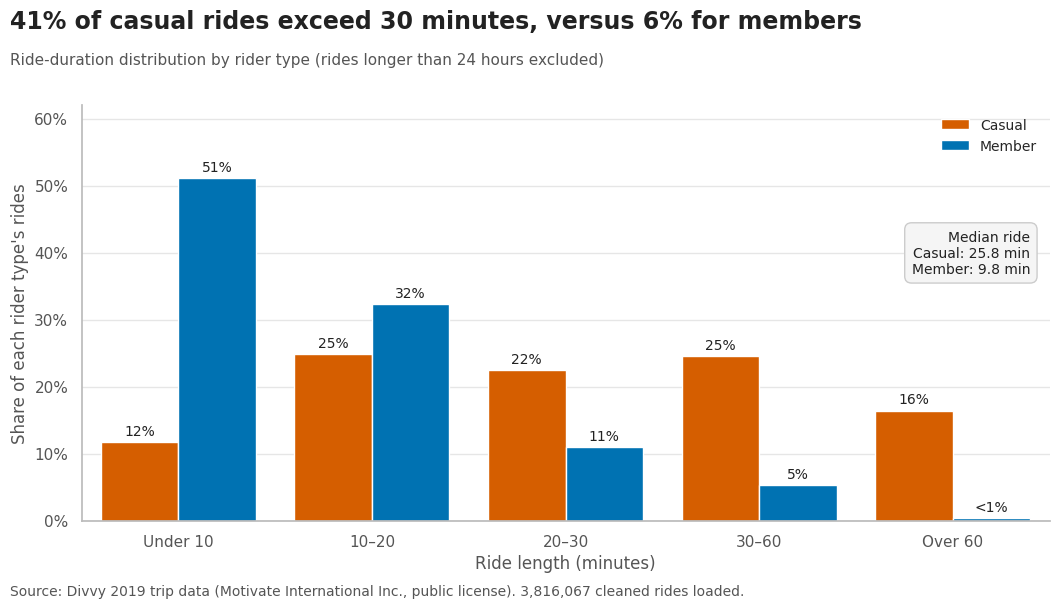

Saved: /kaggle/working/charts/04_ride_length.png
INSIGHT: Median ride duration is 25.8 minutes for casual riders and 9.8 minutes for members. Rides longer than 30 minutes account for 40.9% of casual rides and 5.7% of member rides.


In [9]:
# Ride-duration distribution

duration_data = df.dropna(subset=["ride_length_min", "rider"]).copy()

# Retain the original analysis rule: exclude rides longer than 24 hours.
duration_data = duration_data[
    duration_data["ride_length_min"].between(0, 24 * 60, inclusive="both")
]

if duration_data.empty:
    raise ValueError("No valid ride-duration records remain after applying the 24-hour limit.")

duration_bins = [0, 10, 20, 30, 60, np.inf]
duration_labels = ["Under 10", "10–20", "20–30", "30–60", "Over 60"]
duration_data["bucket"] = pd.cut(
    duration_data["ride_length_min"],
    bins=duration_bins,
    labels=duration_labels,
    right=False
)

bucket_counts = (
    duration_data.groupby(["rider", "bucket"], observed=False)
    .size()
    .rename("rides")
    .reset_index()
)
bucket_counts["pct"] = (
    bucket_counts["rides"]
    / bucket_counts.groupby("rider", observed=True)["rides"].transform("sum")
    * 100
)

over30_share = (
    duration_data.assign(over30=duration_data["ride_length_min"] > 30)
    .groupby("rider")["over30"]
    .mean() * 100
)
median_duration = duration_data.groupby("rider")["ride_length_min"].median()

fig, ax = plt.subplots(figsize=(11, 6.2))
sns.barplot(
    data=bucket_counts,
    x="bucket", y="pct",
    hue="rider", hue_order=RIDER_ORDER,
    order=duration_labels,
    palette=PALETTE, saturation=1, ax=ax
)

for container in ax.containers:
    labels = [
        f"{value:.0f}%" if value >= 1 else ("<1%" if value > 0 else "0%")
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels, padding=3, fontsize=10, color=INK)

ax.set_xlabel("Ride length (minutes)")
ax.set_ylabel("Share of each rider type's rides")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0f}%"))
max_bucket_pct = float(bucket_counts["pct"].max())
ax.set_ylim(0, max(62, max_bucket_pct * 1.20))
ax.legend(title=None, frameon=False, loc="upper right", fontsize=10)

casual_median = median_duration.get("Casual", np.nan)
member_median = median_duration.get("Member", np.nan)
ax.text(
    0.98, 0.70,
    f"Median ride\nCasual: {casual_median:.1f} min\nMember: {member_median:.1f} min",
    transform=ax.transAxes, ha="right", va="top",
    fontsize=10, color=INK,
    bbox=dict(boxstyle="round,pad=0.5", fc="#F5F5F5", ec="#CCCCCC")
)

sns.despine(ax=ax)
fig.subplots_adjust(top=0.81, bottom=0.14, left=0.08, right=0.96)

casual_over30 = over30_share.get("Casual", np.nan)
member_over30 = over30_share.get("Member", np.nan)

add_figure_header(
    fig,
    (
        f"{casual_over30:.0f}% of casual rides exceed 30 minutes, "
        f"versus {member_over30:.0f}% for members"
    ),
    "Ride-duration distribution by rider type (rides longer than 24 hours excluded)"
)

duration_insight = (
    f"Median ride duration is {casual_median:.1f} minutes for casual riders and "
    f"{member_median:.1f} minutes for members. Rides longer than 30 minutes account "
    f"for {casual_over30:.1f}% of casual rides and {member_over30:.1f}% of member rides."
)
duration_alt = (
    "Grouped bar chart showing ride-duration buckets for casual and member riders. "
    f"Median duration: casual {casual_median:.1f} minutes and member {member_median:.1f} minutes. "
    f"More than 30-minute rides: casual {casual_over30:.1f}%, member {member_over30:.1f}%. "
    "Rides longer than 24 hours are excluded."
)

save_chart(fig, "04_ride_length", duration_alt, duration_insight)


## Top starting stations and export

Shows the ten stations with the highest casual ride counts, writes the consolidated alt text, and creates a ZIP of the chart outputs.

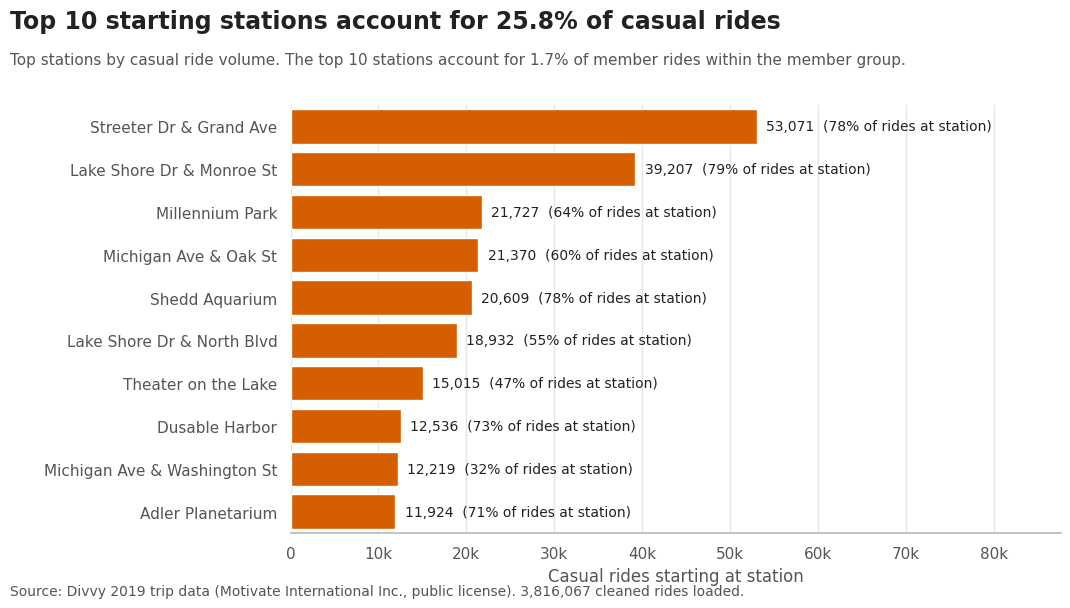

Saved: /kaggle/working/charts/05_top_stations.png
INSIGHT: Streeter Dr & Grand Ave ranks first with 53,071 casual rides. Across the top 10 stations, 25.8% of all casual rides start at one of these locations. At Streeter Dr & Grand Ave, casual riders account for 78.1% of all recorded rides.
Alt text saved: /kaggle/working/charts/alt_text.md
Chart package created: /kaggle/working/cyclistic_phase5_charts.zip
FINAL CHECK: All five chart cells should now be saved in the charts/ folder.
To download the ZIP in Google Colab, run:
from google.colab import files
files.download('/kaggle/working/cyclistic_phase5_charts.zip')


In [10]:
# Top 10 starting stations for casual riders + export all chart notes

station_data = df.dropna(subset=["start_station_name", "rider"]).copy()
station_data["start_station_name"] = (
    station_data["start_station_name"].astype("string").str.strip()
)
station_data = station_data[station_data["start_station_name"].ne("")]

if station_data.empty:
    raise ValueError("No valid starting-station records are available.")

casual_station_counts = (
    station_data.loc[station_data["rider"] == "Casual"]
    .groupby("start_station_name", observed=True)
    .size()
    .sort_values(ascending=False)
)
all_station_counts = (
    station_data.groupby("start_station_name", observed=True)
    .size()
)
member_station_counts = (
    station_data.loc[station_data["rider"] == "Member"]
    .groupby("start_station_name", observed=True)
    .size()
)

if casual_station_counts.empty:
    raise ValueError("No casual rider records are available for the station analysis.")

top10 = casual_station_counts.head(10)
top10_share_at_station = (
    top10 / all_station_counts.reindex(top10.index) * 100
)
casual_total = int(casual_station_counts.sum())
casual_top10_contribution = float(top10.sum() / casual_total * 100)

member_total = int(member_station_counts.sum())
member_top10_contribution = (
    float(member_station_counts.head(10).sum() / member_total * 100)
    if member_total else np.nan
)

# Sort ascending so the highest-volume station appears at the top of the horizontal chart.
plot_counts = top10.sort_values(ascending=True)
plot_shares = top10_share_at_station.reindex(plot_counts.index)

fig, ax = plt.subplots(figsize=(11, 6.2))
sns.barplot(
    x=plot_counts.values,
    y=plot_counts.index.astype(str),
    order=plot_counts.index.astype(str),
    color=CASUAL,
    saturation=1,
    orient="h",
    ax=ax
)
ax.invert_yaxis()

x_offset = max(float(top10.max()) * 0.02, 1)
for position, (rides, casual_pct) in enumerate(zip(plot_counts.values, plot_shares.values)):
    ax.text(
        rides + x_offset, position,
        f"{rides:,}  ({casual_pct:.0f}% of rides at station)",
        va="center", fontsize=10, color=INK
    )

ax.set_xlim(0, float(top10.max()) * 1.65)
ax.set_xlabel("Casual rides starting at station")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(FuncFormatter(compact_count))
sns.despine(ax=ax, left=True)
fig.subplots_adjust(top=0.81, bottom=0.12, left=0.27, right=0.97)

top_station = str(top10.index[0])
top_station_rides = int(top10.iloc[0])
top_station_casual_pct = float(top10_share_at_station.iloc[0])

add_figure_header(
    fig,
    f"Top 10 starting stations account for {casual_top10_contribution:.1f}% of casual rides",
    (
        f"Top stations by casual ride volume. The top 10 stations account for "
        f"{member_top10_contribution:.1f}% of member rides within the member group."
        if not np.isnan(member_top10_contribution)
        else "Top stations by casual ride volume."
    )
)

station_insight = (
    f"{top_station} ranks first with {top_station_rides:,} casual rides. "
    f"Across the top 10 stations, {casual_top10_contribution:.1f}% of all casual rides "
    f"start at one of these locations. At {top_station}, casual riders account for "
    f"{top_station_casual_pct:.1f}% of all recorded rides."
)
station_alt = (
    f"Horizontal bar chart of the ten starting stations with the most casual rides. "
    f"The leading station is {top_station} with {top_station_rides:,} casual rides. "
    f"The top 10 stations account for {casual_top10_contribution:.1f}% of casual rides. "
    f"At the leading station, {top_station_casual_pct:.1f}% of rides are made by casual riders."
)

save_chart(fig, "05_top_stations", station_alt, station_insight)

# Write a consolidated alt-text file after all five chart cells have been executed.
alt_path = OUT_DIR / "alt_text.md"
with alt_path.open("w", encoding="utf-8") as output_file:
    output_file.write("# Cyclistic Capstone — Chart alt text and insights\n\n")
    for chart_name in [
        "01_seasonality",
        "02_weekday",
        "03_hourly",
        "04_ride_length",
        "05_top_stations",
    ]:
        if chart_name in ALT:
            output_file.write(f"## {chart_name}.png\n\n")
            output_file.write(f"{ALT[chart_name]}\n\n")
        else:
            output_file.write(
                f"## {chart_name}.png\n\n"
                "_Run the corresponding chart cell to generate this description._\n\n"
            )

# Package the PNGs and alt text for convenient download from Colab.
from zipfile import ZipFile, ZIP_DEFLATED

zip_path = BASE_DIR / "cyclistic_phase5_charts.zip"
with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as zip_file:
    for output_path in sorted(OUT_DIR.glob("*")):
        if output_path.is_file():
            zip_file.write(output_path, arcname=f"charts/{output_path.name}")

print(f"Alt text saved: {alt_path}")
print(f"Chart package created: {zip_path}")
print("FINAL CHECK: All five chart cells should now be saved in the charts/ folder.")
print("To download the ZIP in Google Colab, run:")
print("from google.colab import files")
print(f"files.download('{zip_path}')")


In [11]:
"""
Cyclistic Capstone | Phase 5: Tableau-optimized extract
Input : trips_2019_clean.(parquet|pkl) from phase3_process.py
Output: tableau_rides.csv  (tall + narrow, flags pre-computed, human-readable labels)

Why row-level? Tableau's MEDIAN and the "ride-length threshold" parameter need
individual rides. Why narrow? Tableau (Hyper) is fastest on few, low-cardinality
columns, so all heavy logic is computed here, not in Tableau calculated fields.
"""
from pathlib import Path
import pandas as pd

IN_DIR, OUT_FILE = Path("."), Path("tableau_rides.csv")
COMMUTE_HOURS = [7, 8, 9, 16, 17, 18]

pq, pk = IN_DIR / "trips_2019_clean.parquet", IN_DIR / "trips_2019_clean.pkl"
df = pd.read_parquet(pq) if pq.exists() else pd.read_pickle(pk)

out = pd.DataFrame({
    "ride_date": df["started_at"].dt.normalize(),
    "rider_type": df["member_casual"].astype(str).map({"casual": "Casual", "member": "Member"}),
    "month_num": df["month"].astype("int8"),
    "month_name": df["month_name"].astype(str),
    "season": df["season"].astype(str),
    "weekday_mon1": (df["started_at"].dt.dayofweek + 1).astype("int8"),   # 1=Mon ... 7=Sun (sort key)
    "weekday_name": df["day_name"].astype(str),
    "day_type": df["is_weekend"].map({True: "Weekend", False: "Weekday"}),
    "hour": df["hour"].astype("int8"),
    "time_window": ((~df["is_weekend"]) & df["hour"].isin(COMMUTE_HOURS)).map(
        {True: "Commute hours", False: "Other hours"}),
    "trip_type": df["is_round_trip"].map({True: "Round trip", False: "Point-to-point"}),
    "ride_length_min": df["ride_length_min"].round(2).astype("float32"),
    "start_station_id": df["start_station_id"].astype("int32"),   # kept for an optional lat/long join
    "start_station": df["start_station_name"].astype(str),
})

out.to_csv(OUT_FILE, index=False, date_format="%Y-%m-%d")
size_mb = OUT_FILE.stat().st_size / 1e6
print(f"Wrote {OUT_FILE} | {len(out):,} rows x {out.shape[1]} cols | {size_mb:,.0f} MB")

# ---- Reconciliation targets: your Tableau KPIs must match these -------------
g = out.groupby("rider_type")
chk = pd.DataFrame({
    "rides": g.size(),
    "median_min": g["ride_length_min"].median(),
    "pct_over_30min": g["ride_length_min"].apply(lambda s: (s > 30).mean() * 100),
    "pct_commute_hours": g["time_window"].apply(lambda s: (s == "Commute hours").mean() * 100),
    "pct_round_trip": g["trip_type"].apply(lambda s: (s == "Round trip").mean() * 100),
})
print("\nReconciliation targets (Tableau should match):\n", chk.round(1).to_string())
ml = ((out.time_window == "Commute hours") & (out.trip_type == "Point-to-point")
      & (out.ride_length_min <= 30) & (out.rider_type == "Casual")).sum()
print(f"\nMember-like casual rides (threshold 30): {ml:,}")


Wrote tableau_rides.csv | 3,816,067 rows x 14 cols | 431 MB

Reconciliation targets (Tableau should match):
               rides  median_min  pct_over_30min  pct_commute_hours  pct_round_trip
rider_type                                                                        
Casual       879262        25.8            40.9               21.3            11.9
Member      2936805         9.8             5.7               47.6             1.6

Member-like casual rides (threshold 30): 118,580
